# Evolution run progress

Edit the parameters below and run all cells. Requires pandas, matplotlib and seaborn (available in the project environment). Paths are resolved from either the repository root or the `notebooks` directory. The checkpoint contains only stored candidates, not every attempted evaluation. Timestamps are candidate creation times after evaluation; generation numbers are assigned when work starts, so concurrent work may finish out of order.

In [11]:
# Parameters
RESULTS_DIR = "results_20261031_185853/local_kmer_plan3"
LOWER_IS_BETTER = True

# Innovation analysis: samples are evenly spaced across best-so-far updates.
INNOVATION_SAMPLES = 8
INNOVATION_MODEL = "gpt-6.1-terra"
EVOLVABLE_FILES = ["new_algorithm/main.cpp"]  # from local_kmer_plan3/config.py
RUN_INNOVATION_ANALYSIS = True  # Set True to make paid API calls.
INNOVATION_CACHE = "innovation_cache.json"  # Stored in the notebooks directory.

In [12]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
from IPython.display import display

path = Path(RESULTS_DIR).expanduser()
if not path.is_absolute() and not path.exists():
    path = Path.cwd().parent / path
state_path = path / "database_state.json"
if not state_path.is_file():
    raise FileNotFoundError(f"Cannot find {state_path.resolve()}; set RESULTS_DIR to the directory containing database_state.json")
state = json.loads(state_path.read_text())
df = pd.DataFrame(state.get("programs", []))
if df.empty:
    raise ValueError("No programs in database_state.json")
df["combined_score"] = pd.to_numeric(df["combined_score"], errors="coerce")
df["timestamp"] = pd.to_numeric(df["timestamp"], errors="coerce")
df = df.sort_values(["timestamp", "generation", "id"], na_position="last").reset_index(drop=True)
df["elapsed_hours"] = (df.timestamp - df.timestamp.min()) / 3600
df["valid_score"] = df.correct.fillna(False).astype(bool) & np.isfinite(df.combined_score)
valid = df[df.valid_score].copy()
if valid.empty:
    raise ValueError("No correct programs with finite combined scores")
valid["best_so_far"] = valid.combined_score.cummin() if LOWER_IS_BETTER else valid.combined_score.cummax()
score_by_id = df.set_index("id").combined_score
valid["parent_score"] = valid.parent_id.map(score_by_id)
valid["improvement"] = (valid.parent_score - valid.combined_score) * (1 if LOWER_IS_BETTER else -1)
best = valid.loc[valid.combined_score.idxmin() if LOWER_IS_BETTER else valid.combined_score.idxmax()]
print(f"Results: {path.resolve()}\nStored programs: {len(df)}; correct finite scores: {len(valid)}")
print(f"Best: {best.combined_score:.6g} (generation {best.generation}, id {best.id})")
print(f"Checkpoint global best: {state.get('global_best_id')} | Direction: {'lower' if LOWER_IS_BETTER else 'higher'} is better")
if state.get('global_best_id') != best.id:
    print('Note: checkpoint best differs from computed best (ties or score direction may explain this).')

Results: /Users/zia1138/adrevo/results_20261031_185853/local_kmer_plan3
Stored programs: 119; correct finite scores: 119
Best: 0.41723 (generation 146, id eb085fa4-1feb-42aa-a0b3-ae6d9d34dbdc)
Checkpoint global best: eb085fa4-1feb-42aa-a0b3-ae6d9d34dbdc | Direction: lower is better


## Progress over completion time

The running best is calculated in timestamp order, using correct finite scores. Points represent stored candidates, including non-improvements.

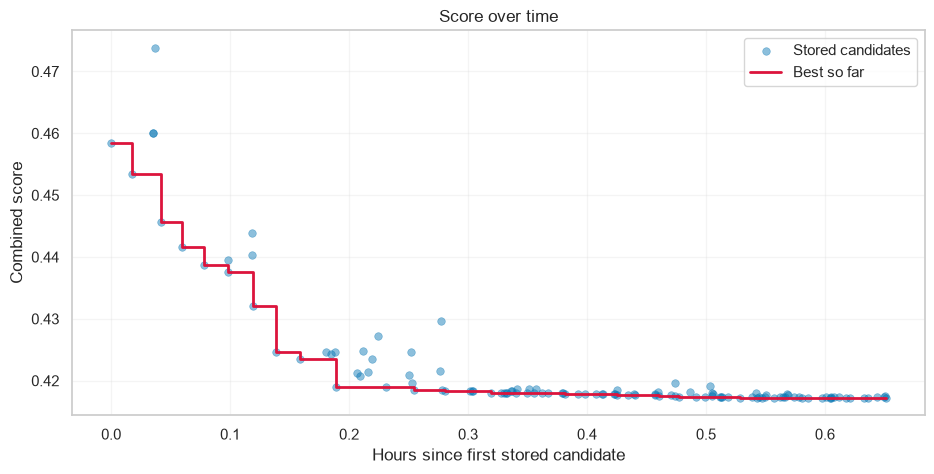

In [13]:
fig, ax = plt.subplots(figsize=(11, 5))
sns.scatterplot(data=valid, x="elapsed_hours", y="combined_score", alpha=.45, s=30, edgecolor=None, label="Stored candidates", ax=ax)
ax.step(valid.elapsed_hours, valid.best_so_far, where="post", color="crimson", linewidth=2, label="Best so far")
ax.set(xlabel="Hours since first stored candidate", ylabel="Combined score", title="Score over time")
ax.legend(); ax.grid(alpha=.2); plt.show()

## Best score so far

The step curve follows candidate completion timestamps. Save the figure as a vector PDF or a high-resolution PNG using the commented lines below.

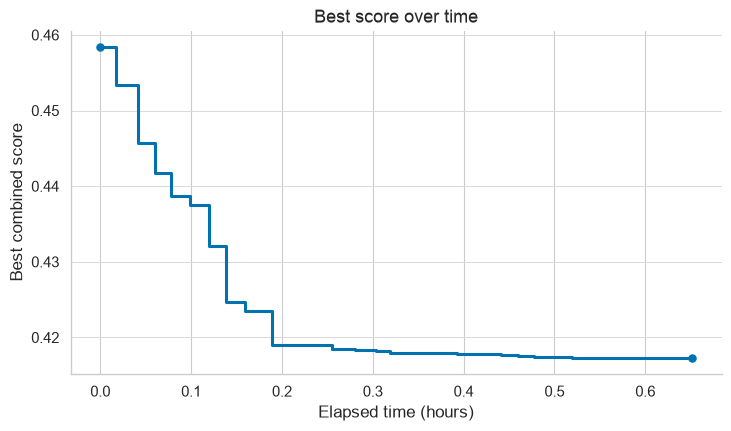

In [14]:
with sns.axes_style("whitegrid"), sns.plotting_context("paper", font_scale=1.25), plt.rc_context({
    "font.size": 11, "axes.labelsize": 12, "axes.titlesize": 13,
    "axes.spines.top": False, "axes.spines.right": False,
    "pdf.fonttype": 42, "ps.fonttype": 42,
}):
    fig, ax = plt.subplots(figsize=(7.2, 4.2), layout="constrained")
    ax.step(valid.elapsed_hours, valid.best_so_far, where="post",
            color="#0072B2", linewidth=2.2)
    ax.scatter([valid.elapsed_hours.iloc[0], valid.elapsed_hours.iloc[-1]],
               [valid.best_so_far.iloc[0], valid.best_so_far.iloc[-1]],
               color="#0072B2", s=28, zorder=3)
    ax.set(xlabel="Elapsed time (hours)", ylabel="Best combined score",
           title="Best score over time")
    ax.grid(axis="y", color="#d9d9d9", linewidth=0.7)
    ax.set_axisbelow(True)
    # fig.savefig("best_score.pdf", bbox_inches="tight")
    # fig.savefig("best_score.png", dpi=300, bbox_inches="tight")
    plt.show()

## Generation and parent comparisons

Multiple candidates can share a generation. Positive parent improvement always means a better score, regardless of direction.

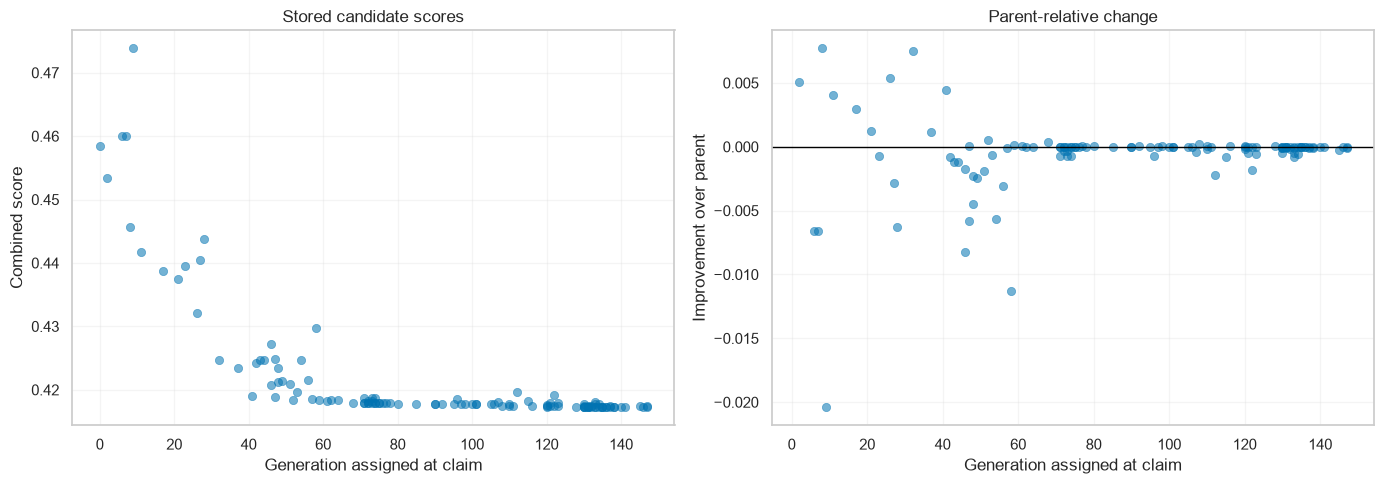

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=valid, x="generation", y="combined_score", alpha=.55, edgecolor=None, ax=axes[0])
axes[0].set(xlabel="Generation assigned at claim", ylabel="Combined score", title="Stored candidate scores")
children = valid[valid.parent_score.notna()]
sns.scatterplot(data=children, x="generation", y="improvement", alpha=.55, edgecolor=None, ax=axes[1])
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set(xlabel="Generation assigned at claim", ylabel="Improvement over parent", title="Parent-relative change")
for ax in axes: ax.grid(alpha=.2)
plt.tight_layout(); plt.show()

## Models and timings

Counts cover stored candidates only. Inference time is measured from the start of the parent claim and can include prior turns and evaluations; it is not necessarily a single model call duration. Compute time is evaluator runtime.

,candidates,parent_improvements,median_score,median_inference_s,median_compute_s
model_id,,,,,
gpt-6.1-terra-medium,114,29,0.417927,64.515702,7.126323
gpt-6.1-terra-high,4,1,0.417288,180.557378,7.098022
initial,1,0,0.458460,0.000000,30.194952


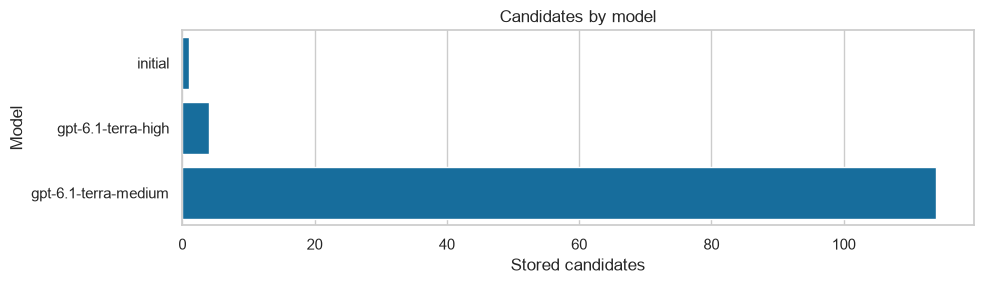

In [16]:
models = valid.groupby("model_id", dropna=False).agg(candidates=("id", "size"), parent_improvements=("improvement", lambda x: (x > 0).sum()), median_score=("combined_score", "median"), median_inference_s=("inference_time", "median"), median_compute_s=("compute_time", "median")).sort_values("candidates", ascending=False)
display(models)
fig, ax = plt.subplots(figsize=(10, max(3, len(models)*.5)))
sns.barplot(x=models.candidates.sort_values().values, y=models.candidates.sort_values().index, color=sns.color_palette("colorblind")[0], ax=ax)
ax.set(xlabel="Stored candidates", ylabel="Model", title="Candidates by model"); plt.tight_layout(); plt.show()

## Best lineage

Follow parent IDs from the computed best candidate. Missing parents are reported; the final checkpoint's focus and branch history cannot be reconstructed from these links alone.

,generation,id,parent_id,model_id,combined_score
0,0,176e5a03-843f-47b2-8729-5e45c6008340,NaN,initial,0.458460
1,2,a4e7d46c-3de1-4e49-8d81-f820f04cb253,176e5a03-843f-47b2-8729-5e45c6008340,gpt-6.1-terra-medium,0.453424
2,8,d9e3e44b-3cd4-43d8-9c91-03e8e5de97f6,a4e7d46c-3de1-4e49-8d81-f820f04cb253,gpt-6.1-terra-medium,0.445723
3,11,4e5cc575-6987-4476-bfa2-581d8c9e7229,d9e3e44b-3cd4-43d8-9c91-03e8e5de97f6,gpt-6.1-terra-medium,0.441691
4,17,15fdf3ab-953b-4eed-a83f-c0eacf66f5eb,4e5cc575-6987-4476-bfa2-581d8c9e7229,gpt-6.1-terra-medium,0.438737
5,21,5592d0a7-8664-4269-9cab-5fc6fba6d0ce,15fdf3ab-953b-4eed-a83f-c0eacf66f5eb,gpt-6.1-terra-medium,0.437519
6,26,e72b9609-f793-40ef-9b44-d2540d26963d,5592d0a7-8664-4269-9cab-5fc6fba6d0ce,gpt-6.1-terra-medium,0.432128
7,32,5e05fabe-5fbe-41a7-bd0a-8fa5c2dbc208,e72b9609-f793-40ef-9b44-d2540d26963d,gpt-6.1-terra-medium,0.424619
8,37,8f8ed795-87c9-4ed7-bb53-0398a19126ad,5e05fabe-5fbe-41a7-bd0a-8fa5c2dbc208,gpt-6.1-terra-medium,0.423427
9,41,2d1119f2-c69f-4b6d-9bac-554f244f62ec,8f8ed795-87c9-4ed7-bb53-0398a19126ad,gpt-6.1-terra-medium,0.418962


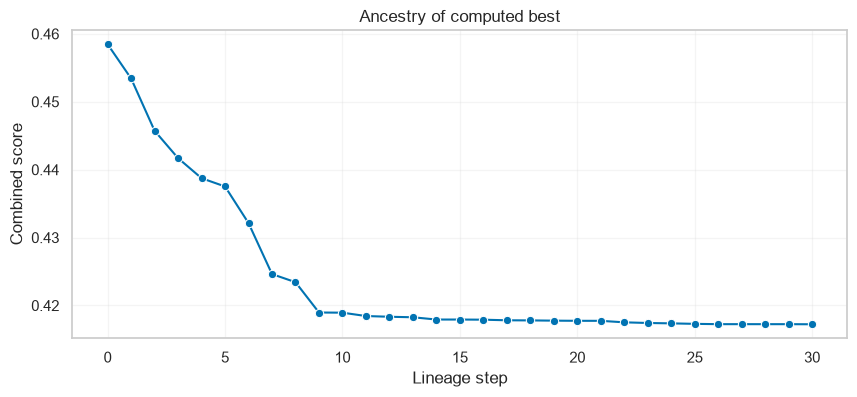

In [17]:
by_id = df.set_index("id", drop=False)
lineage, seen, current = [], set(), best.id
while isinstance(current, str) and current:
    if current in seen or current not in by_id.index:
        print(f"Lineage stopped at missing or repeated ID: {current}")
        break
    seen.add(current)
    row = by_id.loc[current]
    lineage.append(row)
    current = row.parent_id
lineage = pd.DataFrame(lineage[::-1])
display(lineage[["generation", "id", "parent_id", "model_id", "combined_score"]].reset_index(drop=True))
fig, ax = plt.subplots(figsize=(10, 4))
sns.lineplot(x=range(len(lineage)), y=lineage.combined_score, marker="o", ax=ax)
ax.set(xlabel="Lineage step", ylabel="Combined score", title="Ancestry of computed best")
ax.grid(alpha=.2); plt.show()

## Checkpoint usage

Usage is an aggregate checkpoint, not per candidate. Carried cost represents earlier segments after resume; token counts shown are for the current segment.

In [18]:
usage_path = path / "evogen_state.json"
if usage_path.exists():
    usage = json.loads(usage_path.read_text())
    rows = []
    for model, prices in usage.get("model_costs", {}).items():
        inp = usage.get("input_tokens", {}).get(model, 0)
        out = usage.get("output_tokens", {}).get(model, 0)
        rows.append({"model": model, "input_tokens": inp, "output_tokens": out, "estimated_cost": (inp * prices[0] + out * prices[1]) / 1e6})
    usage_df = pd.DataFrame(rows)
    if not usage_df.empty:
        display(usage_df.set_index("model"))
    print(f"Carried cost: ${usage.get('carried_cost', 0):.4f}; total estimated cost: ${usage.get('carried_cost', 0) + sum(r['estimated_cost'] for r in rows):.4f}")
else:
    print("No evogen_state.json found; usage unavailable.")

,input_tokens,output_tokens,estimated_cost
model,,,
gpt-6-astra-high,0,0,0.000000
gpt-6-astra-medium,0,0,0.000000
gpt-6.1-sol-high,0,0,0.000000
gpt-6.1-sol-medium,0,0,0.000000
gpt-6.1-terra-high,132223,126876,0.383302
gpt-6.1-terra-medium,2789113,1309127,4.667374


Carried cost: $0.0000; total estimated cost: $5.0507


## Innovations in sampled best candidates

Set `RUN_INNOVATION_ANALYSIS = True` in the parameters and rerun the notebook to call the model. This sends candidate source code and diffs to the model provider and incurs API charges; an OpenAI API key and `pydantic-ai` are required. The samples are evenly spaced by **best-so-far update**, including the first and last. Each description compares a sample with the preceding sampled checkpoint, so it can summarize multiple intervening changes; the first describes the baseline. The table is sorted best score first. Model descriptions are hypotheses, not proof that a change caused the score improvement. Update `EVOLVABLE_FILES` for another run.

Descriptions are cached in `INNOVATION_CACHE` in the notebooks directory. Entries are reused only when the model and exact prompt match. Delete the cache to regenerate them.

In [19]:
if RUN_INNOVATION_ANALYSIS:
    import difflib
    import hashlib
    import zipfile
    from pydantic_ai import Agent
    from pydantic_ai.models.openai import OpenAIResponsesModel

    if not isinstance(INNOVATION_SAMPLES, int) or INNOVATION_SAMPLES < 2:
        raise ValueError("INNOVATION_SAMPLES must be an integer of at least 2")
    if not EVOLVABLE_FILES:
        raise ValueError("Set EVOLVABLE_FILES to the archive paths to analyze")
    # Strict records in completion order; ties do not count as new records.
    previous_best = valid.best_so_far.shift()
    records = valid[previous_best.isna() | (valid.best_so_far != previous_best)].copy()
    indices = np.unique(np.linspace(0, len(records) - 1,
                                    min(INNOVATION_SAMPLES, len(records))).round().astype(int))
    samples = records.iloc[indices]
    system_prompt = ("You are a careful source-code analyst. Describe the main algorithmic "
                     "innovation in the current code compared with the previous sample in "
                     "at most eight words. Be concrete. If no meaningful change, say so. "
                     "For the initial sample describe its core method. Return only the description.")
    cache_path = (Path.cwd() if Path.cwd().name == "notebooks" else Path.cwd() / "notebooks") / INNOVATION_CACHE
    cache = json.loads(cache_path.read_text(encoding="utf-8")) if cache_path.exists() else {}
    if not isinstance(cache, dict):
        raise ValueError(f"Invalid innovation cache: {cache_path}")
    agent = Agent(
        OpenAIResponsesModel(INNOVATION_MODEL), output_type=str,
        system_prompt=system_prompt,
    )
    results, previous_files = [], None
    for _, sample in samples.iterrows():
        archive_path = path / f"{sample.id}.zip"
        if not archive_path.is_file():
            raise FileNotFoundError(f"Missing candidate archive: {archive_path}")
        with zipfile.ZipFile(archive_path) as archive:
            files = {}
            for name in EVOLVABLE_FILES:
                try:
                    files[name] = archive.read(name).decode("utf-8")
                except KeyError as exc:
                    raise KeyError(f"{name!r} missing from {archive_path}") from exc
        if previous_files is None:
            payload = "\n\n".join(f"File: {name}\n{content}" for name, content in files.items())
            prompt = "Describe the initial implementation:\n" + payload
        else:
            payload = "\n".join(
                "".join(difflib.unified_diff(previous_files[name].splitlines(keepends=True),
                                             content.splitlines(keepends=True),
                                             fromfile=f"previous/{name}", tofile=f"current/{name}"))
                for name, content in files.items()
            )
            prompt = "Describe the main innovation compared with the previous sampled checkpoint:\n" + (payload or "No source changes.")
        cache_key = hashlib.sha256(json.dumps(
            {"model": INNOVATION_MODEL, "system_prompt": system_prompt, "prompt": prompt},
            sort_keys=True, ensure_ascii=False
        ).encode("utf-8")).hexdigest()
        if cache_key in cache:
            description = cache[cache_key]
        else:
            res = await agent.run(prompt)
            description = res.output.strip()
            cache[cache_key] = description
            # Save after every response so interrupted runs retain completed work.
            temp_path = cache_path.with_suffix(cache_path.suffix + ".tmp")
            temp_path.write_text(json.dumps(cache, indent=2, ensure_ascii=False), encoding="utf-8")
            temp_path.replace(cache_path)
        results.append({"score": sample.combined_score, "generation": sample.generation,
                        "program_id": sample.id, "innovation": description})
        previous_files = files
    innovations = pd.DataFrame(results).sort_values("score", ascending=LOWER_IS_BETTER).reset_index(drop=True)
    display(innovations)
else:
    print("Innovation analysis is disabled. Set RUN_INNOVATION_ANALYSIS = True to run it.")

,score,generation,program_id,innovation
0,0.417230,146,eb085fa4-1feb-42aa-a0b3-ae6d9d34dbdc,Enumerates missing prefixes to restore suppres...
1,0.417246,128,0a4728a5-b866-44ee-890b-67fd304828b5,"Narrower secondary minima, guaranteed left-pri..."
2,0.417737,100,c44eb0bf-28b1-416b-a44c-3f8544b235b9,Tightens boundary-seed survival requirements; ...
3,0.417816,80,7c18c796-4b65-495b-82e5-a597d069c449,Enumerates DNA extensions to assess neighborin...
4,0.418261,61,b7108cba-f7ab-4307-9d76-59d81dc7f06a,Weighted hash minima with redundancy suppressi...
5,0.418962,41,2d1119f2-c69f-4b6d-9bac-554f244f62ec,Selects central submer minima using lagged has...
6,0.438737,17,15fdf3ab-953b-4eed-a83f-c0eacf66f5eb,Decrements s; rejects syncmers with nearby sec...
7,0.458460,0,176e5a03-843f-47b2-8729-5e45c6008340,Selects 21-mers with minimum SHA-256-ranked s-...


## Best score and sampled innovations

Labels identify sampled record-setting candidates. Each description compares the candidate with the previous sample, and does not establish causality. Run the innovation analysis above first.

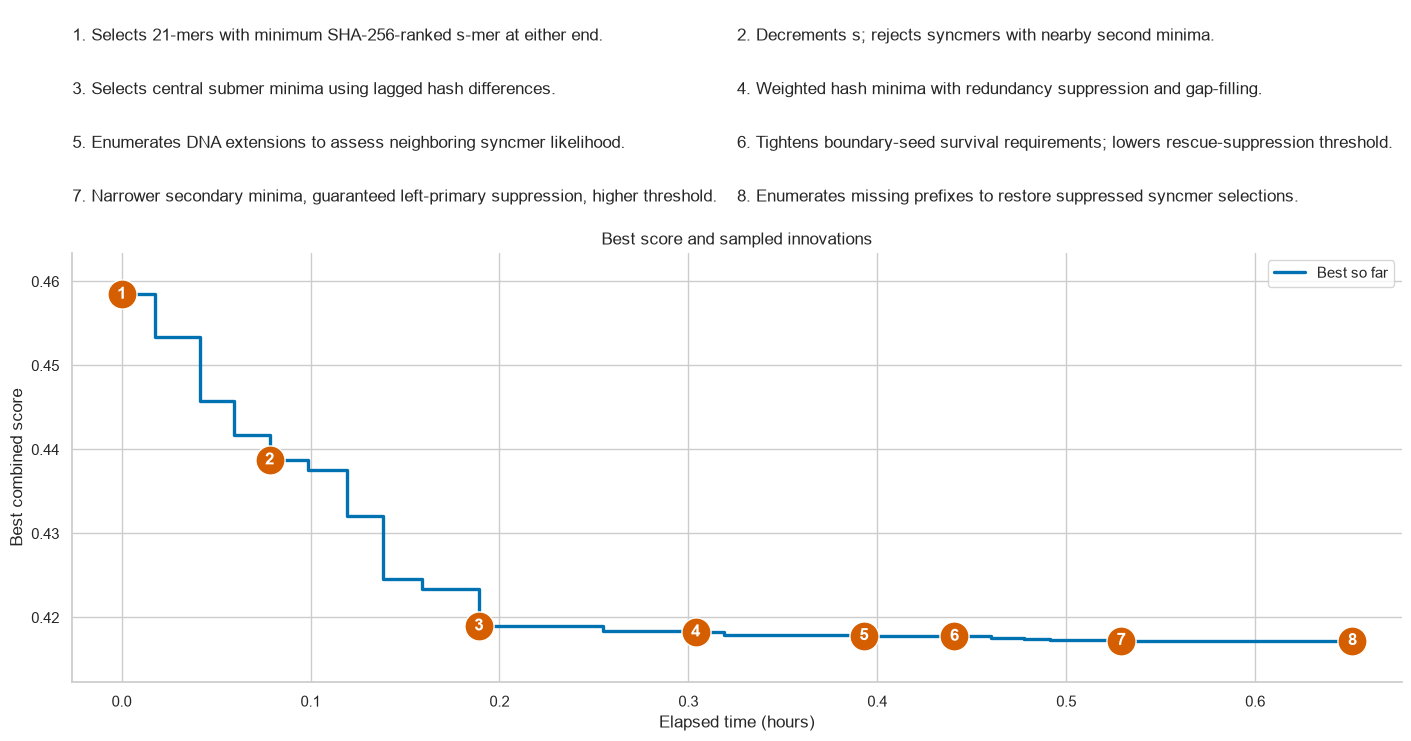

In [20]:
if not RUN_INNOVATION_ANALYSIS or "innovations" not in globals() or innovations.empty:
    print("Run the innovation analysis above to display this plot.")
else:
    annotated = innovations.merge(
        valid[["id", "elapsed_hours"]], left_on="program_id", right_on="id",
        how="left", validate="one_to_one"
    ).sort_values("elapsed_hours")
    if annotated.elapsed_hours.isna().any():
        raise ValueError("Innovation results do not match this run; rerun the innovation analysis.")
    # Numbered markers connect labels to points without crossing leader lines.
    with sns.axes_style("whitegrid"), sns.plotting_context("notebook"):
        fig = plt.figure(figsize=(14, max(7, 4.5 + len(annotated) * 0.35)), layout="constrained")
        grid = fig.add_gridspec(2, 1, height_ratios=[max(1.5, len(annotated) * 0.25), 4])
        labels_ax = fig.add_subplot(grid[0])
        ax = fig.add_subplot(grid[1])
        labels_ax.axis("off")
        ax.step(valid.elapsed_hours, valid.best_so_far, where="post",
                color="#0072B2", linewidth=2.4, label="Best so far")
        ax.scatter(annotated.elapsed_hours, annotated.score, color="#D55E00",
                   edgecolor="white", linewidth=1, s=440, zorder=3)
        for i, row in enumerate(annotated.itertuples(), start=1):
            ax.annotate(str(i), (row.elapsed_hours, row.score),
                        ha="center", va="center", color="white", fontsize=12,
                        fontweight="bold", zorder=4)
            # Two columns provide generous room for readable descriptions.
            col = (i - 1) % 2
            rank = (i - 1) // 2
            nrows = (len(annotated) + 1) // 2
            labels_ax.text(col * 0.5, 1 - (rank + 0.5) / nrows,
                           f"{i}. {row.innovation}", transform=labels_ax.transAxes,
                           fontsize=12, ha="left", va="center", wrap=True)
        ax.set(xlabel="Elapsed time (hours)", ylabel="Best combined score",
               title="Best score and sampled innovations")
        ax.margins(x=0.04, y=0.12)
        ax.legend(loc="best")
        sns.despine(ax=ax)
        fig.savefig("best_score_innovations.pdf", bbox_inches="tight")
        # fig.savefig("best_score_innovations.png", dpi=300, bbox_inches="tight")
        plt.show()